# Chapter 6: Welfare Theorems, Efficiency, and the Second Best

This notebook reruns four worked examples from the chapter: trades toward the Pareto frontier, the deadweight triangle of a parking tax, a second-best transit subsidy, and a safety mandate under hidden action. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def edgeworth_box(ax, width, height, endowment=None, allocation=None, xlabel="Good x (person A from left)",
                  ylabel="Good y (person A from bottom)"):
    """Box of size width x height with optional endowment and allocation points."""
    ax.plot([0, width, width, 0, 0], [0, 0, height, height, 0], color=PALETTE["ink"], linewidth=1.2)
    if endowment is not None:
        mark(ax, endowment[0], endowment[1], "Endowment", col="gold")
    if allocation is not None:
        mark(ax, allocation[0], allocation[1], "Allocation", col="teal")
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def plus(value, digits=2, comma=True):
    """Number with an explicit sign for changes: '+0.42', '-0.20', '0.00'."""
    text = num(value, digits, comma)
    return text if text.startswith("-") or float(text.replace(",", "")) == 0 else f"+{text}"


def edgeworth_linear(uA, uB, alloc, totals=(8, 8)):
    """Linear utilities in a two-good exchange economy.

    uA, uB are (weight on bread, weight on cheese); alloc is A's bundle (b_A, c_A) and B gets
    totals minus it. Principle: pareto-criterion. Book (ch006): u_A = 2b + c, u_B = b + 2c,
    (4, 4) each gives 12 and 12; A at (5, 3) gives 13 and 13; (8, 0) gives 16 and 16; A at (5, 4)
    with B at (3, 4) gives 14 and 11.
    Returns dict with bundles and utilities.
    """
    bA, cA = alloc
    bB, cB = totals[0] - bA, totals[1] - cA
    return {"A": (bA, cA), "B": (bB, cB), "uA": uA[0] * bA + uA[1] * cA, "uB": uB[0] * bB + uB[1] * cB}


def deadweight_loss(t, dQ):
    """Harberger triangle 0.5 t dQ. Principle: deadweight-loss. Book (ch006): 0.5(4)(2,000) = 4,000."""
    return 0.5 * t * dQ


def linear_tax_wedge(a, b, c, d, t):
    """Per-unit tax t in a market with inverse demand P = a - bQ and inverse supply P = c + dQ.

    Principle: deadweight-loss. Book (ch006): a=20, b=0.10, c=4, d=0.10 (Q in hundreds of visits),
    t=4 gives Q0 = 80, Q_t = 60, buyer price 14, seller price 10, revenue 240, CS 180, PS 180,
    DWL 40 (hundreds of dollars: 24,000, 18,000, 18,000, 4,000).
    """
    q0 = (a - c) / (b + d)
    q = max((a - c - t) / (b + d), 0.0)
    pd, ps = a - b * q, c + d * q
    return {"q0": q0, "p0": a - b * q0, "q": q, "pd": pd, "ps": ps, "revenue": t * q,
            "cs": 0.5 * (a - pd) * q, "ps_surplus": 0.5 * (ps - c) * q, "dwl": deadweight_loss(t, q0 - q),
            "total0": 0.5 * (a - c) * q0}


plt.rcParams.update(HOUSE_RC)


equilibrium = SimpleNamespace(edgeworth_linear=edgeworth_linear, deadweight_loss=deadweight_loss, linear_tax_wedge=linear_tax_wedge)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'pareto-criterion': {'totals': (8, 8),
                      'uA': (2, 1),
                      'uB': (1, 2),
                      'start': (4, 4),
                      'u_start': 12,
                      'after_one': ((5, 3), (3, 5)),
                      'u_after_one': 13,
                      'corner': ((8, 0), (0, 8)),
                      'u_corner': 16,
                      'grab': ((5, 4), (3, 4)),
                      'u_grab': (14, 11)},
 'deadweight-loss': {'demand': (20, 0.1),
                     'supply': (4, 0.1),
                     'q0': 80,
                     'p0': 12,
                     'total0': 640,
                     't': 4,
                     'q_t': 60,
                     'visits': 6000,
                     'buyer': 14,
                     'seller': 10,
                     'revenue': 24000,
                     'cs': 18000,
                     'ps': 18000,
                     'total_t': 60000,
                     'dwl': 4000,
                     'damage': 3,
                     'avoided': 6000,
                     'net_gain': 2000},
 'general-theory-of-second-best': {'congestion': 12,
                                   'operating': 6,
                                   'convenience': 2,
                                   'subsidy': 8,
                                   'net': 4,
                                   'lam': 0.75,
                                   'funds': 6,
                                   'net_lam': -2,
                                   'toll': 12},
 'greenwald-stiglitz-constrained-inefficiency': {'n': 100,
                                                 'loss': 100,
                                                 'p0': 0.1,
                                                 'p1': 0.04,
                                                 'cost': 3,
                                                 'solo_saving': 0.06,
                                                 'premium_none': 10,
                                                 'total_none': 1000,
                                                 'premium_mandate': 4,
                                                 'total_mandate': 700,
                                                 'gain': 300,
                                                 'enforcement': 4,
                                                 'total_enforced': 1100},
 'constructed': {'pareto-criterion': {'swaps': [2], 'grab_after_swaps': True},
                 'deadweight-loss': {'t': [2, 6]},
                 'general-theory-of-second-best': {'lam': [0.25]},
                 'greenwald-stiglitz-constrained-inefficiency': {'enforcement': [2]}}}


def pareto_picture(k=1, grab="no"):
    uA, uB = (2, 1), (1, 2)
    start = equilibrium.edgeworth_linear(uA, uB, (4, 4))
    feasible = not (grab == "yes" and 4 - k - 1 < 0)
    taken = 1 if grab == "yes" and feasible else 0
    res = equilibrium.edgeworth_linear(uA, uB, (4 + k + taken, 4 - k))
    dA, dB = res["uA"] - start["uA"], res["uB"] - start["uB"]
    improves = dA >= 0 and dB >= 0 and (dA > 0 or dB > 0)
    fig, ax = new_figure()
    edgeworth_box(ax, 8, 8, xlabel="Bread loaves held by A (B holds the rest)",
                  ylabel="Cheese wedges held by A (B holds the rest)")
    ax.plot([0, 8], [8, 0], color=PALETTE["light"], linewidth=1.2, linestyle="dotted")
    mark(ax, 4, 4, "start (4, 4)", col="grey", dx=-8, dy=-12, ha="right", va="top")
    if res["A"] not in ((4, 4), (8, 0)):
        mark(ax, res["A"][0], res["A"][1], f"A ({res['A'][0]}, {res['A'][1]})", col="teal",
             dx=-8 if res["A"][0] >= 7 else 8, dy=8, ha="right" if res["A"][0] >= 7 else "left")
    mark(ax, 8, 0, None, col="gold")
    label(ax, 8, 0, "A (8, 0): efficient corner" if res["A"] == (8, 0) else "efficient corner (8, 0)", col="gold",
          dx=-8, dy=8, ha="right")
    ax.text(0.03, 0.96, f"u_A = {res['uA']}  (start 12)\nu_B = {res['uB']}  (start 12)", transform=ax.transAxes,
            ha="left", va="top", fontsize=11, color=PALETTE["ink"],
            bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": PALETTE["light"]})
    ax.set_xlim(-0.2, 8.2)
    ax.set_ylim(-0.2, 8.2)
    verdict = ("a Pareto improvement: both gain" if improves and dA > 0 and dB > 0 else
               "a Pareto improvement: one gains and no one loses" if improves else
               "no change" if dA == 0 and dB == 0 else "not a Pareto improvement: someone loses")
    move = f"{k} {'swap' if k == 1 else 'swaps'} of one cheese wedge for one loaf"
    if grab == "yes" and not feasible:
        extra = " B holds no bread after 4 swaps, so there is no loaf left to take."
    elif grab == "yes":
        extra = " A then takes one more loaf from B without paying."
    else:
        extra = ""
    metrics = {"A holds (bread, cheese)": f"({res['A'][0]}, {res['A'][1]})",
               "B holds (bread, cheese)": f"({res['B'][0]}, {res['B'][1]})",
               "u_A": str(res["uA"]), "u_B": str(res["uB"]), "Pareto improvement on (4, 4)": "yes" if improves else "no"}
    interp = (f"After {move}.{extra} A holds ({res['A'][0]}, {res['A'][1]}) so u_A = 2 x {res['A'][0]} + "
              f"{res['A'][1]} = {res['uA']}; B holds ({res['B'][0]}, {res['B'][1]}) so u_B = {res['B'][0]} + 2 x "
              f"{res['B'][1]} = {res['uB']}. Against 12 and 12 at the start this is {verdict}.")
    steps = [f"A: 2 x {res['A'][0]} + {res['A'][1]} = {res['uA']} (change {plus(dA, 0)})",
             f"B: {res['B'][0]} + 2 x {res['B'][1]} = {res['uB']} (change {plus(dB, 0)})",
             "Pareto improvement: " + ("yes" if improves else "no")]
    alt = (f"Edgeworth box of 8 loaves and 8 wedges. A's bundle is ({res['A'][0]}, {res['A'][1]}); utilities are "
           f"{res['uA']} for A and {res['uB']} for B.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def tax_picture(t=4, dmg=0):
    r = equilibrium.linear_tax_wedge(20, 0.10, 4, 0.10, t)
    q0, q = r["q0"], r["q"]
    cut = 100 * (q0 - q)
    dwl = 100 * r["dwl"]
    avoided = dmg * cut
    net = avoided - dwl
    qs = np.linspace(0, 160, 200)
    fig, ax = new_figure()
    ax.fill_between([0, q], [r["pd"], r["pd"]], [20, 20 - 0.10 * q], color=PALETTE["navy"], alpha=0.15)
    ax.fill_between([0, q], [4, 4 + 0.10 * q], [r["ps"], r["ps"]], color=PALETTE["teal"], alpha=0.15)
    if t > 0:
        ax.fill_between([0, q], [r["ps"]] * 2, [r["pd"]] * 2, color=PALETTE["gold"], alpha=0.25)
        ax.fill([q, q0, q], [r["pd"], r["p0"], r["ps"]], color=PALETTE["terracotta"], alpha=0.45)
    ax.plot(qs, 20 - 0.10 * qs, color=PALETTE["navy"], linewidth=2.2, label="demand P = 20 - 0.10Q")
    ax.plot(qs, 4 + 0.10 * qs, color=PALETTE["teal"], linewidth=2.2, label="supply P = 4 + 0.10Q")
    if dmg:
        ax.plot(qs, 4 + dmg + 0.10 * qs, color=PALETTE["grey"], linewidth=1.4, linestyle="dashed",
                label=f"social cost with damage {money(dmg, 0)}")
    if t > 0:
        mark(ax, q, r["pd"], f"buyers pay {money(r['pd'], 0)}", col="navy", dx=-8, dy=6, ha="right")
        mark(ax, q, r["ps"], f"sellers get {money(r['ps'], 0)}", col="teal", dx=-8, dy=-8, ha="right", va="top")
    mark(ax, q0, r["p0"], "no tax (80, 12)", col="ink", dx=8, dy=6)
    ax.set_xlim(0, 160)
    ax.set_ylim(0, 22)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Daily visits Q (hundreds)")
    ax.set_ylabel("Price per visit ($)")
    visits = 100 * q
    rev, cs, ps = 100 * r["revenue"], 100 * r["cs"], 100 * r["ps_surplus"]
    verdict = ("the no-tax baseline itself, so nothing changes" if t == 0 else
               f"a net social gain of {money(net, 0)}" if net > 0 else
               "exactly zero net gain: the avoided damage equals the lost surplus" if net == 0 else
               f"a net social loss of {money(-net, 0)}")
    metrics = {"Visits": num(visits, 0), "Buyer price": money(r["pd"], 0), "Seller price": money(r["ps"], 0),
               "Tax revenue": money(rev, 0), "Consumer surplus": money(cs, 0), "Producer surplus": money(ps, 0),
               "Deadweight loss": money(dwl, 0), "Avoided damage": money(avoided, 0),
               "Net gain over no tax": money(net, 0)}
    interp = (f"With a tax of {t}, 20 - 0.10Q - (4 + 0.10Q) = {t} gives Q = {num(q, 0)} hundred, {num(visits, 0)} "
              f"visits. Revenue is {t} x {num(visits, 0)} = {money(rev, 0)}. The triangle is 0.5 x {t} x "
              f"{num(cut, 0)} = {money(dwl, 0)}. Damage of {dmg} per visit avoided on {num(cut, 0)} visits is "
              f"{money(avoided, 0)}, so against no tax the result is {verdict}.")
    steps = [f"Q = (16 - {t}) / 0.20 = {num(q, 0)} hundred",
             f"Buyer price = 20 - 0.10 x {num(q, 0)} = {num(r['pd'], 0)}; seller price = {num(r['ps'], 0)}",
             f"Revenue = {t} x {num(visits, 0)} = {num(rev, 0)}",
             f"DWL = 0.5 x {t} x {num(cut, 0)} = {num(dwl, 0)}",
             f"Avoided damage = {dmg} x {num(cut, 0)} = {num(avoided, 0)}",
             f"Net = {num(avoided, 0)} - {num(dwl, 0)} = {num(net, 0)}"]
    alt = (f"Parking market with a {money(t, 0)} tax: {num(visits, 0)} visits, buyers pay {money(r['pd'], 0)}, "
           f"sellers get {money(r['ps'], 0)}, deadweight triangle {money(dwl, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def second_best(lam, toll, ext=12, cost=6, conv=2, subsidy=8):
    """Net welfare per trip of the transit subsidy (principle: general-theory-of-second-best).

    Book (ch006): 12 - 6 - 2 = 4 with free funds; 12 - 6 - 2 - 0.75 x 8 = -2. With a toll the
    switch happens without a subsidy, so no funds are raised.
    """
    funds = 0.0 if toll == "yes" else lam * subsidy
    return {"congestion": ext, "operating": cost, "convenience": conv, "funds": funds,
            "net": ext - cost - conv - funds, "breakeven_lam": (ext - cost - conv) / subsidy}


def secondbest_picture(lam=0, toll="no"):
    r = second_best(lam, toll)
    names = ["Congestion saved", "Extra operating cost", "Lost convenience", "Cost of funds", "Net welfare"]
    vals = [r["congestion"], -r["operating"], -r["convenience"], -r["funds"], r["net"]]
    fig, ax = new_figure()
    level = 0.0
    for i, (n, v) in enumerate(zip(names, vals)):
        if i == len(vals) - 1:
            bottom, height = 0.0, v
            col = PALETTE["teal"] if v >= 0 else PALETTE["terracotta"]
        else:
            bottom, height = level, v
            level += v
            col = PALETTE["navy"] if v >= 0 else PALETTE["gold"]
        ax.bar(i, height, bottom=bottom, color=col, width=0.6)
        top = bottom + max(height, 0)
        ax.annotate(money(v, 2) if v != int(v) else money(v, 0), (i, max(bottom, bottom + height)),
                    xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=10.5)
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(range(len(names)), ["Congestion\nsaved", "Operating\ncost", "Convenience", "Cost of\nfunds", "Net"])
    ax.set_ylim(-4, 15)
    ax.set_xlabel("Effect of moving one trip from car to train")
    ax.set_ylabel("Dollars per trip")
    fund_txt = (f"{lam} x 8 = {num(r['funds'], 0)}" if toll == "no" else "0 (no subsidy is needed)")
    if toll == "yes":
        why = (" With a $12 toll the driver faces the congestion cost directly and switches with no subsidy, so no "
               "funds are raised and the cost of funds does not matter.")
    else:
        why = f" The subsidy breaks even when the cost per dollar is 4 / 8 = {num(r['breakeven_lam'], 2)}."
    sign = ("gains" if r["net"] > 0 else "loses" if r["net"] < 0 else "breaks even at")
    metrics = {"Cost of funds": money(r["funds"], 0), "Net welfare per trip": money(r["net"], 0),
               "Break-even cost per subsidy dollar": num(r["breakeven_lam"], 2), "Road toll": toll}
    fund_expr = (f"{lam} x 8" if toll == "no" else "0")
    note = "" if toll == "no" else " (no subsidy is needed)"
    interp = (f"Net welfare = 12 - 6 - 2 - {fund_expr} = {num(r['net'], 0)}{note}, so society {sign} "
              f"{money(abs(r['net']), 0)} per trip." if r["net"] != 0 else
              f"Net welfare = 12 - 6 - 2 - {fund_expr} = 0{note}, so the subsidy exactly breaks even.") + why
    steps = ["Resource gain = 12 - 6 - 2 = 4", f"Cost of funds = {fund_txt}",
             f"Net = 4 - {num(r['funds'], 0)} = {num(r['net'], 0)}"]
    alt = (f"Waterfall of one trip moved from car to train: congestion saved 12, operating cost 6, convenience 2, "
           f"cost of funds {num(r['funds'], 0)}, net {num(r['net'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def safety_pool(regime, enf, n=100, loss=100, p0=0.10, p1=0.04, c=3):
    """Pool real cost and premium under no policy, a mandate or telematics.

    Principle: greenwald-stiglitz-constrained-inefficiency. Book (ch006): one driver acting alone
    cuts the premium by 6 / 100 = 0.06; no action costs 1,000 with premium 10; the mandate costs
    100(3) + 100(0.04)(100) = 700 with premium 4; enforcement of 4 raises it to 1,100.
    """
    acts = regime != "none"
    p = p1 if acts else p0
    prevention = n * c if acts else 0.0
    accidents = n * p * loss
    enforcement = n * enf if regime == "mandate" else 0.0
    return {"prevention": prevention, "accidents": accidents, "enforcement": enforcement,
            "total": prevention + accidents + enforcement, "premium": p * loss,
            "solo_saving": (p0 - p1) * loss / n}


def safety_picture(regime="mandate", enf=0):
    base = safety_pool("none", 0)
    r = safety_pool(regime, enf)
    gain = base["total"] - r["total"]
    names = ["No policy", {"none": "No policy", "mandate": "Mandate", "telematics": "Telematics"}[regime]]
    fig, ax = new_figure()
    parts = [(base, 0), (r, 1)]
    for res, i in parts:
        bottom = 0
        for key, col, lab in [("prevention", "teal", "prevention"), ("accidents", "terracotta", "accident loss"),
                              ("enforcement", "gold", "enforcement")]:
            if res[key] > 0:
                ax.bar(i, res[key], bottom=bottom, color=PALETTE[col], width=0.5, label=lab if i == 1 or key == "accidents" else None)
                bottom += res[key]
        ax.annotate(tex_safe(f"{money(res['total'], 0)}, premium {money(res['premium'], 0)}"), (i, bottom), xytext=(0, 4),
                    textcoords="offset points", ha="center", va="bottom", fontsize=10.5)
    handles, labels = ax.get_legend_handles_labels()
    seen = {}
    for h, l in zip(handles, labels):
        seen.setdefault(l, h)
    ax.legend(seen.values(), seen.keys(), loc="upper left", frameon=False)
    ax.set_xticks([0, 1], names)
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0, 1_500)
    ax.set_xlabel("Policy")
    ax.set_ylabel("Real cost for the pool of 100 ($)")
    if regime == "none":
        detail = ("No one acts: a driver acting alone pays 3 to cut the shared premium by 6 / 100 = 0.06. Real cost is "
                  "100 x 0.10 x 100 = 1,000 and the premium is 10.")
    elif regime == "mandate":
        detail = (f"Real cost = 100 x 3 + 100 x 0.04 x 100 + 100 x {enf} = {num(r['total'], 0)}, against 1,000 with "
                  "no policy: " + (f"a gain of {money(gain, 0)}." if gain > 0 else "no gain at all." if gain == 0
                                   else f"a loss of {money(-gain, 0)}."))
    else:
        detail = (f"Telematics verifies each driver, so insurers quote 4 to safe drivers and 10 to others; each driver "
                  f"pays 3 to save 6 and acts. Real cost = 100 x 3 + 100 x 0.04 x 100 = {num(r['total'], 0)}, a gain "
                  f"of {money(gain, 0)}. Enforcement cost does not apply without a mandate.")
    metrics = {"Pool real cost": money(r["total"], 0), "Premium per driver": money(r["premium"], 0),
               "Gain over no policy": money(gain, 0), "Premium cut from acting alone": money(6.0 if regime == "telematics" else r["solo_saving"], 2)}
    interp = detail
    steps = [f"Prevention = {num(r['prevention'], 0)}", f"Accident loss = 100 x {num(r['premium'] / 100, 2)} x 100 = "
             f"{num(r['accidents'], 0)}", f"Enforcement = {num(r['enforcement'], 0)}",
             f"Total = {num(r['prevention'], 0)} + {num(r['accidents'], 0)} + {num(r['enforcement'], 0)} = "
             f"{num(r['total'], 0)}", f"Gain = 1,000 - {num(r['total'], 0)} = {num(gain, 0)}"]
    alt = ("Stacked bars of the pool's real cost: 1,000 with no policy, the baseline itself." if regime == "none"
           else f"Stacked bars of the pool's real cost: 1,000 with no policy against {num(r['total'], 0)} under "
           f"{names[1].lower()}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Pareto criterion: trading bread for cheese

Eight loaves and eight wedges; both start at $(4,4)$.

$$u_A=2b_A+c_A, \qquad u_B=b_B+2c_B$$

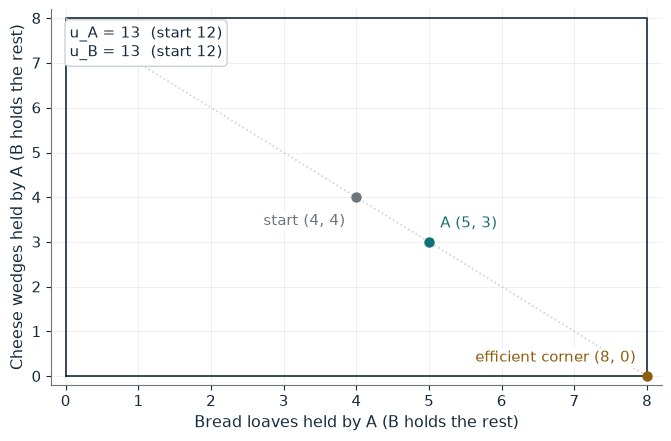

A holds (bread, cheese)       (5, 3)
B holds (bread, cheese)       (3, 5)
u_A                           13
u_B                           13
Pareto improvement on (4, 4)  yes

Worked steps:
  1. A: 2 x 5 + 3 = 13 (change +1)
  2. B: 3 + 2 x 5 = 13 (change +1)
  3. Pareto improvement: yes

After 1 swap of one cheese wedge for one loaf. A holds (5, 3) so u_A = 2 x 5 + 3 = 13; B holds (3, 5) so u_B = 3 + 2 x 5 = 13. Against 12 and 12 at the start this is a Pareto improvement: both gain.


In [2]:
show(pareto_picture(k=1, grab='no'))

Change one input, `k`, and hold the others at the book's values:

In [3]:
sweep(pareto_picture, 'k', [0, 1, 2, 4], {'grab': 'no'}, ['A holds (bread, cheese)', 'u_A', 'u_B', 'Pareto improvement on (4, 4)'])

k | A holds (bread, cheese) | u_A | u_B | Pareto improvement on (4, 4)
0 | (4, 4) | 12 | 12 | no
1 | (5, 3) | 13 | 13 | yes
2 | (6, 2) | 14 | 14 | yes
4 | (8, 0) | 16 | 16 | yes


Each swap raises both utilities: 13 and 13 after one, 16 and 16 at the corner. Taking a loaf unpaid from the start gives 14 and 11, which fails the Pareto test.

## 2. Deadweight loss of a parking tax

$P_D=20-0.10Q$ and $P_S=4+0.10Q$, with $Q$ in hundreds of visits. With a \$4 tax:

$$(20-0.10Q)-(4+0.10Q)=4, \qquad \frac{1}{2}(\$4)(2{,}000)=\$4{,}000$$

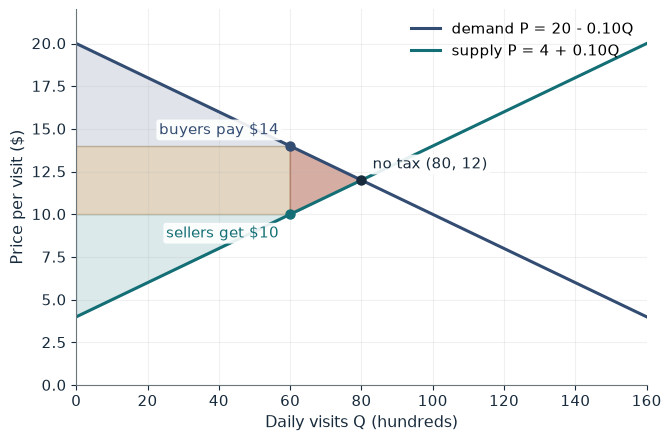

Visits                6,000
Buyer price           $14
Seller price          $10
Tax revenue           $24,000
Consumer surplus      $18,000
Producer surplus      $18,000
Deadweight loss       $4,000
Avoided damage        $0
Net gain over no tax  -$4,000

Worked steps:
  1. Q = (16 - 4) / 0.20 = 60 hundred
  2. Buyer price = 20 - 0.10 x 60 = 14; seller price = 10
  3. Revenue = 4 x 6,000 = 24,000
  4. DWL = 0.5 x 4 x 2,000 = 4,000
  5. Avoided damage = 0 x 2,000 = 0
  6. Net = 0 - 4,000 = -4,000

With a tax of 4, 20 - 0.10Q - (4 + 0.10Q) = 4 gives Q = 60 hundred, 6,000 visits. Revenue is 4 x 6,000 = $24,000. The triangle is 0.5 x 4 x 2,000 = $4,000. Damage of 0 per visit avoided on 2,000 visits is $0, so against no tax the result is a net social loss of $4,000.


In [4]:
show(tax_picture(t=4, dmg=0))

Change one input, `t`, and hold the others at the book's values:

In [5]:
sweep(tax_picture, 't', [0, 2, 4, 6], {'dmg': 3}, ['Visits', 'Deadweight loss', 'Avoided damage', 'Net gain over no tax'])

t | Visits | Deadweight loss | Avoided damage | Net gain over no tax
0 | 8,000 | $0 | $0 | $0
2 | 7,000 | $1,000 | $3,000 | $2,000
4 | 6,000 | $4,000 | $6,000 | $2,000
6 | 5,000 | $9,000 | $9,000 | $0


The \$4 tax cuts visits from 8,000 to 6,000 and destroys \$4,000 of surplus. With \$3 of congestion damage per visit it avoids \$6,000 of harm, a \$2,000 net gain; a \$6 tax nets zero.

## 3. General theory of second best: the transit subsidy

$$\$12-\$6-\$2=\$4, \qquad \$12-\$6-\$2-\$6=-\$2$$

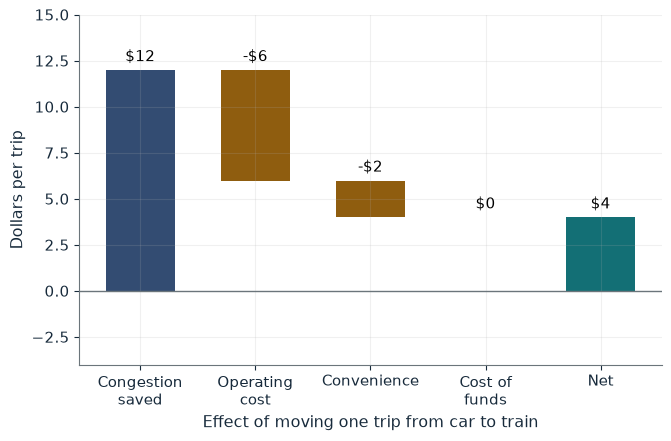

Cost of funds                       $0
Net welfare per trip                $4
Break-even cost per subsidy dollar  0.50
Road toll                           no

Worked steps:
  1. Resource gain = 12 - 6 - 2 = 4
  2. Cost of funds = 0 x 8 = 0
  3. Net = 4 - 0 = 4

Net welfare = 12 - 6 - 2 - 0 x 8 = 4, so society gains $4 per trip. The subsidy breaks even when the cost per dollar is 4 / 8 = 0.50.


In [6]:
show(secondbest_picture(lam=0, toll='no'))

Change one input, `lam`, and hold the others at the book's values:

In [7]:
sweep(secondbest_picture, 'lam', [0, 0.25, 0.75], {'toll': 'no'}, ['Cost of funds', 'Net welfare per trip'])

lam | Cost of funds | Net welfare per trip
0 | $0 | $4
0.25 | $2 | $2
0.75 | $6 | -$2


With free funds the subsidy gains \$4 a trip; at 0.75 per dollar it loses \$2. It breaks even at 0.5. A \$12 toll removes the need for the subsidy.

## 4. Greenwald-Stiglitz: a mandate for hidden safety

A driver acting alone cuts the shared premium by only $\frac{\$6}{100}=\$0.06$. Under a mandate:

$$100(\$3)+100(0.04)(\$100)=\$700$$

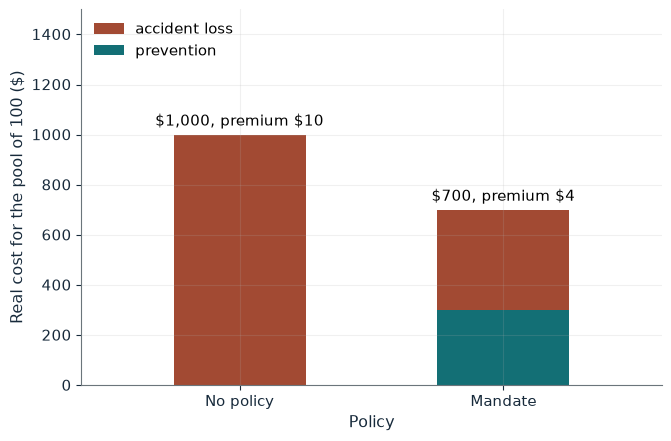

Pool real cost                 $700
Premium per driver             $4
Gain over no policy            $300
Premium cut from acting alone  $0.06

Worked steps:
  1. Prevention = 300
  2. Accident loss = 100 x 0.04 x 100 = 400
  3. Enforcement = 0
  4. Total = 300 + 400 + 0 = 700
  5. Gain = 1,000 - 700 = 300

Real cost = 100 x 3 + 100 x 0.04 x 100 + 100 x 0 = 700, against 1,000 with no policy: a gain of $300.


In [8]:
show(safety_picture(regime='mandate', enf=0))

Change one input, `enf`, and hold the others at the book's values:

In [9]:
sweep(safety_picture, 'enf', [0, 2, 4], {'regime': 'mandate'}, ['Pool real cost', 'Gain over no policy'])

enf | Pool real cost | Gain over no policy
0 | $700 | $300
2 | $900 | $100
4 | $1,100 | -$100


The mandate cuts real cost from \$1,000 to \$700. Enforcement of \$2 per driver leaves a \$100 gain; \$4 turns it into a \$100 loss.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

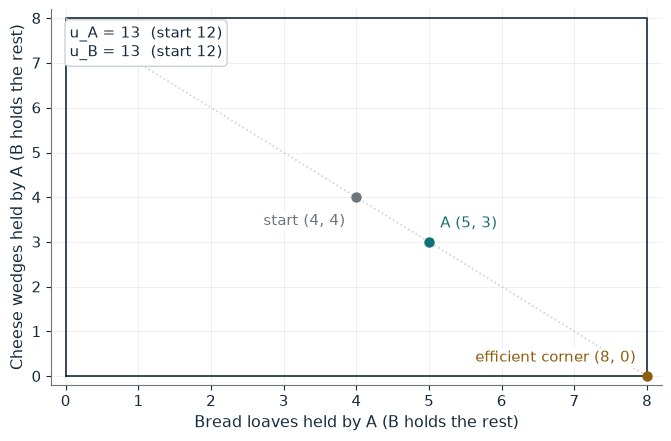

A holds (bread, cheese)       (5, 3)
B holds (bread, cheese)       (3, 5)
u_A                           13
u_B                           13
Pareto improvement on (4, 4)  yes

Worked steps:
  1. A: 2 x 5 + 3 = 13 (change +1)
  2. B: 3 + 2 x 5 = 13 (change +1)
  3. Pareto improvement: yes

After 1 swap of one cheese wedge for one loaf. A holds (5, 3) so u_A = 2 x 5 + 3 = 13; B holds (3, 5) so u_B = 3 + 2 x 5 = 13. Against 12 and 12 at the start this is a Pareto improvement: both gain.


In [10]:
show(pareto_picture(k=1, grab='no'))

## Practice

**1.** After 2 swaps without a grab, what are both utilities?

<details><summary>Answer</summary>

A at (6, 2): 14. B at (2, 6): 14.

</details>

**2.** With a \$6 tax and \$3 damage, what is the net social gain over no tax?

<details><summary>Answer</summary>

Q = 5,000; DWL = 0.5 x 6 x 3,000 = 9,000; avoided damage 9,000; net gain 0.

</details>

**3.** With a cost of funds of 0.25, what is net welfare from the subsidy?

<details><summary>Answer</summary>

12 - 6 - 2 - 0.25 x 8 = 2 per trip.

</details>